# 04. Fraud Analysis & Typology Profiling
**UPI Fraud Detection and Risk Analytics**

### Objectives:
1. Conduct customer-level behavioral aggregation & transaction velocity profiling.
2. Identify high-risk transaction segments using multi-attribute intersection rules.
3. Perform geographic risk analysis across States and Cities.
4. Build a Sender Bank vs. Receiver Bank pairwise vulnerability matrix.
5. Examine the relationship between transaction failure reasons and fraudulent activities.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
%matplotlib inline


## 1. Load Processed Dataset

In [2]:
data_path =  r"C:\UPI Data\UPI_Transactions_Cleaned.csv"
if not os.path.exists(data_path):
    data_path =  r"C:\UPI Data\UPI_Transactions_Cleaned.csv"

df = pd.read_csv(data_path)
print(f'Dataset Loaded: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()


Dataset Loaded: 10000 rows, 24 columns


,Transaction_ID,Transaction_Date,Customer_ID,City,State,Sender_Bank,Receiver_Bank,UPI_App,Transaction_Type,Payment_Method,Amount,Transaction_Status,Failure_Reason,Processing_Time_sec,Bank_Response_Time_ms,Fraud_Label,Year,Month,Month_Name,Day,Day_of_Week,Day_of_Week_Num,Is_Weekend,Quarter
0,TXN100000,2025-11-24,CUST09196,Bengaluru,Karnataka,SBI,Kotak Mahindra Bank,PhonePe,Online Purchase,Mobile Number,2014.53,Success,Not Applicable,4.83,801,0,2025,11,Nov,24,Monday,0,0,4
1,TXN100001,2025-04-23,CUST01520,Ahmedabad,Gujarat,Yes Bank,Kotak Mahindra Bank,BHIM,P2P,UPI ID,1359.97,Success,Not Applicable,1.58,751,0,2025,4,Apr,23,Wednesday,2,0,2
2,TXN100002,2025-06-26,CUST09460,Lucknow,Uttar Pradesh,Kotak Mahindra Bank,SBI,PhonePe,P2P,UPI,8199.06,Success,Not Applicable,3.03,816,0,2025,6,Jun,26,Thursday,3,0,2
3,TXN100003,2025-12-05,CUST05821,Mumbai,Maharashtra,Kotak Mahindra Bank,HDFC Bank,PhonePe,Bill Payment,UPI,2240.06,Success,Not Applicable,3.58,345,0,2025,12,Dec,5,Friday,4,0,4
4,TXN100004,2025-11-08,CUST00526,Kochi,Kerala,ICICI Bank,Union Bank,Paytm,Recharge,UPI ID,320.36,Success,Not Applicable,4.48,888,0,2025,11,Nov,8,Saturday,5,1,4


## 2. Customer Velocity & Aggregation Profiling

In [3]:
cust_profile = df.groupby('Customer_ID').agg(
    Txn_Count=('Fraud_Label', 'count'),
    Total_Amount=('Amount', 'sum'),
    Avg_Amount=('Amount', 'mean'),
    Max_Amount=('Amount', 'max'),
    Fraud_Count=('Fraud_Label', 'sum'),
    Fraud_Rate_Mean=('Fraud_Label', 'mean')
).reset_index()
cust_profile['Fraud_Rate'] = (cust_profile['Fraud_Rate_Mean'] * 100).round(2)

print('Customer Aggregation Summary Statistics:')
display(cust_profile.describe())

print('\nTop 10 High-Risk Customers by Fraud Count:')
display(cust_profile.sort_values(by='Fraud_Count', ascending=False).head(10))


Customer Aggregation Summary Statistics:


,Txn_Count,Total_Amount,Avg_Amount,Max_Amount,Fraud_Count,Fraud_Rate_Mean,Fraud_Rate
count,7228.000000,7228.000000,7228.000000,7228.000000,7228.000000,7228.000000,7228.000000
mean,1.383509,1852.676883,1347.507244,1593.914725,0.013697,0.009638,0.963839
std,0.656935,2309.083578,1775.974845,2072.757929,0.116237,0.088263,8.826268
min,1.000000,26.450000,26.450000,26.450000,0.000000,0.000000,0.000000
25%,1.000000,545.280000,478.202500,514.185000,0.000000,0.000000,0.000000
50%,1.000000,1142.760000,872.805000,979.535000,0.000000,0.000000,0.000000
75%,2.000000,2293.360000,1608.103750,1926.072500,0.000000,0.000000,0.000000
max,5.000000,63776.840000,63776.840000,63776.840000,1.000000,1.000000,100.000000



Top 10 High-Risk Customers by Fraud Count:


,Customer_ID,Txn_Count,Total_Amount,Avg_Amount,Max_Amount,Fraud_Count,Fraud_Rate_Mean,Fraud_Rate
1418,CUST02985,1,591.80,591.800000,591.80,1,1.000000,100.00
1480,CUST03097,2,778.70,389.350000,548.95,1,0.500000,50.00
1626,CUST03411,1,1847.71,1847.710000,1847.71,1,1.000000,100.00
2597,CUST05520,2,1051.37,525.685000,685.50,1,0.500000,50.00
1995,CUST04206,1,444.75,444.750000,444.75,1,1.000000,100.00
307,CUST00644,3,3772.94,1257.646667,2178.80,1,0.333333,33.33
915,CUST01978,2,1491.79,745.895000,985.34,1,0.500000,50.00
837,CUST01827,1,965.42,965.420000,965.42,1,1.000000,100.00
3099,CUST06545,1,751.72,751.720000,751.72,1,1.000000,100.00
2782,CUST05881,4,4172.53,1043.132500,2502.00,1,0.250000,25.00


## 3. Multi-Attribute High-Risk Segment Profiling

In [4]:
# Define segment flags
df['High_Amount'] = df['Amount'] > df['Amount'].quantile(0.85)
df['High_Latency'] = df['Bank_Response_Time_ms'] > df['Bank_Response_Time_ms'].quantile(0.85)
df['Is_Failed'] = df['Transaction_Status'] == 'Failed'

segment_summary = df.groupby(['High_Amount', 'High_Latency', 'Is_Failed']).agg(
    Total_Txns=('Fraud_Label', 'count'),
    Fraud_Txns=('Fraud_Label', 'sum'),
    Fraud_Rate_Mean=('Fraud_Label', 'mean')
).reset_index()
segment_summary['Fraud_Rate_Pct'] = (segment_summary['Fraud_Rate_Mean'] * 100).round(2)
segment_summary = segment_summary.sort_values(by='Fraud_Rate_Pct', ascending=False)

print('Segment Risk Matrix (Sorted by Fraud Rate %):')
display(segment_summary)


Segment Risk Matrix (Sorted by Fraud Rate %):


,High_Amount,High_Latency,Is_Failed,Total_Txns,Fraud_Txns,Fraud_Rate_Mean,Fraud_Rate_Pct
3,False,True,True,95,6,0.063158,6.32
1,False,False,True,519,14,0.026975,2.70
5,True,False,True,76,2,0.026316,2.63
6,True,True,False,203,2,0.009852,0.99
2,False,True,False,1178,11,0.009338,0.93
0,False,False,False,6708,55,0.008199,0.82
4,True,False,False,1204,9,0.007475,0.75
7,True,True,True,17,0,0.000000,0.00


## 4. Geographic Risk Mapping (State & City)

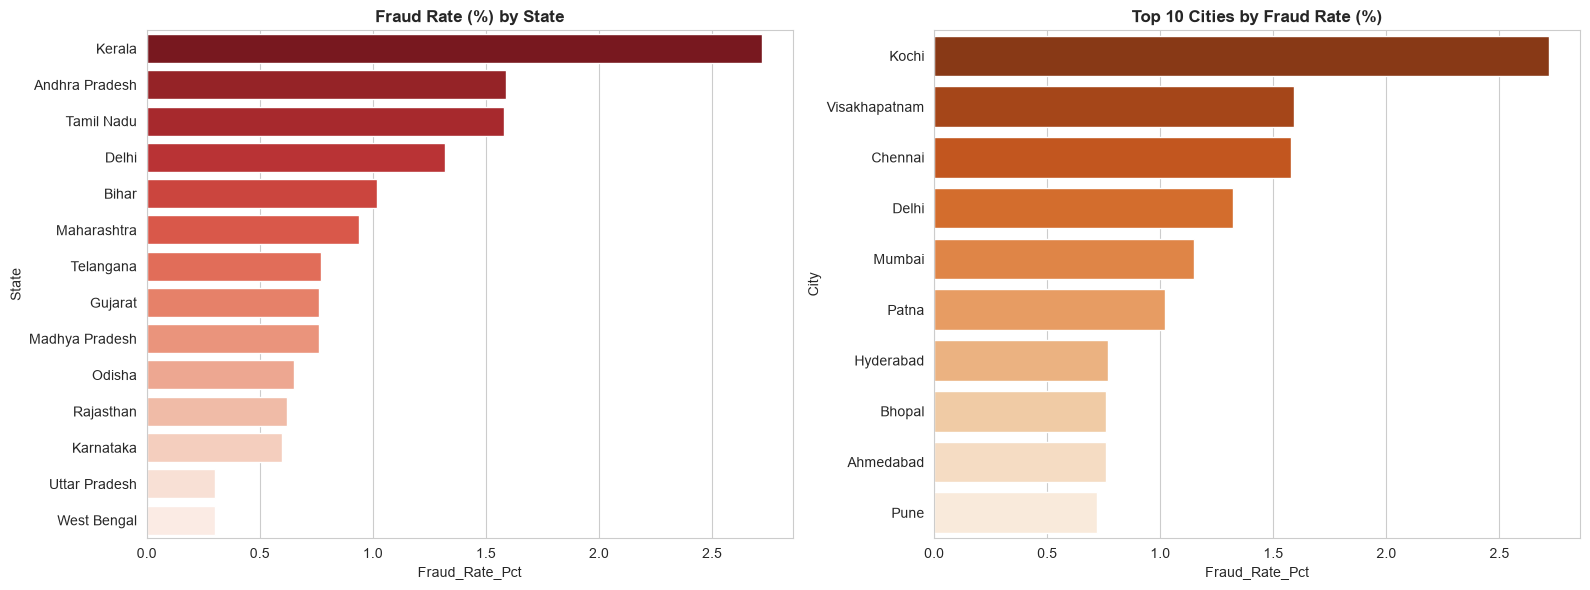

In [8]:
state_risk = df.groupby('State').agg(
    Total_Txns=('Fraud_Label', 'count'),
    Fraud_Txns=('Fraud_Label', 'sum'),
    Fraud_Rate_Mean=('Fraud_Label', 'mean')
).reset_index()
state_risk['Fraud_Rate_Pct'] = (state_risk['Fraud_Rate_Mean'] * 100).round(2)
state_risk = state_risk.sort_values(by='Fraud_Rate_Pct', ascending=False)

city_risk = df.groupby('City').agg(
    Total_Txns=('Fraud_Label', 'count'),
    Fraud_Txns=('Fraud_Label', 'sum'),
    Fraud_Rate_Mean=('Fraud_Label', 'mean')
).reset_index()
city_risk['Fraud_Rate_Pct'] = (city_risk['Fraud_Rate_Mean'] * 100).round(2)
city_risk = city_risk.sort_values(by='Fraud_Rate_Pct', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=state_risk, x='Fraud_Rate_Pct', y='State', hue='State', ax=axes[0], palette='Reds_r', legend=False)
axes[0].set_title('Fraud Rate (%) by State', fontsize=12, fontweight='bold')

sns.barplot(data=city_risk.head(10), x='Fraud_Rate_Pct', y='City', hue='City', ax=axes[1], palette='Oranges_r', legend=False)
axes[1].set_title('Top 10 Cities by Fraud Rate (%)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Bank Interaction Pairwise Vulnerability Matrix

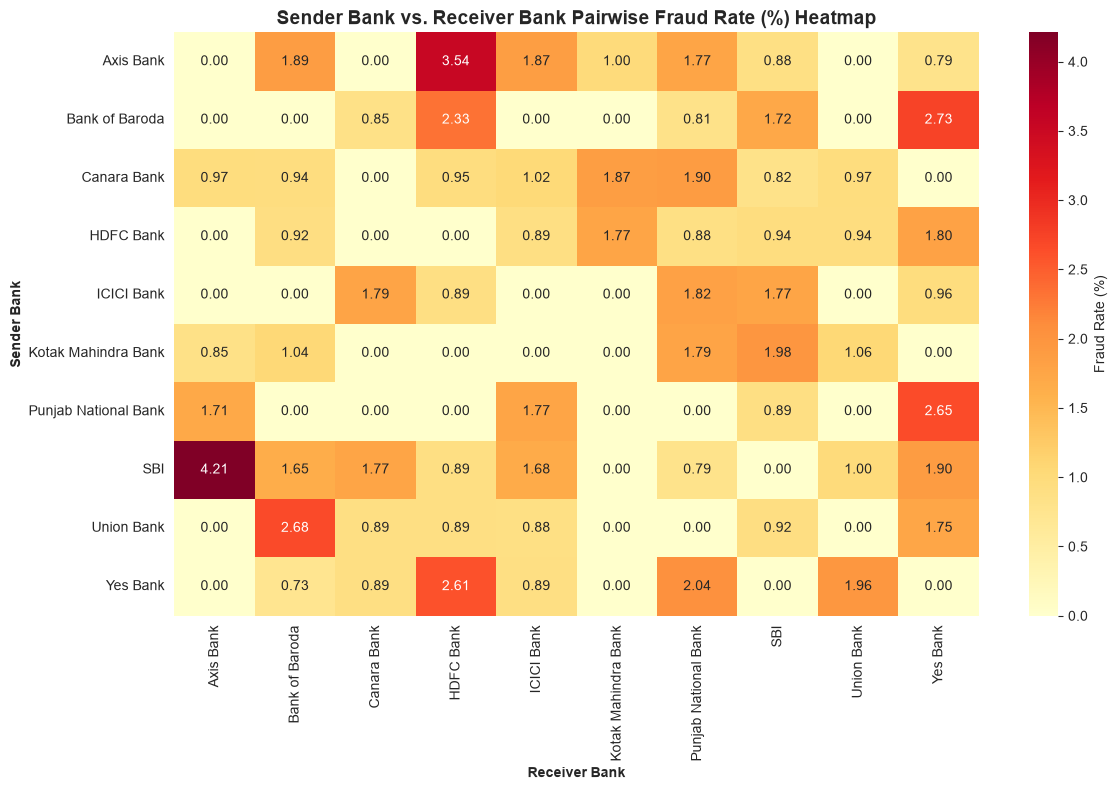

In [9]:
bank_pair_pivot = pd.pivot_table(
    df,
    values='Fraud_Label',
    index='Sender_Bank',
    columns='Receiver_Bank',
    aggfunc=lambda x: round(x.mean() * 100, 2),
    fill_value=0
)

plt.figure(figsize=(12, 8))
sns.heatmap(bank_pair_pivot, annot=True, fmt='.2f', cmap='YlOrRd', cbar_kws={'label': 'Fraud Rate (%)'})
plt.title('Sender Bank vs. Receiver Bank Pairwise Fraud Rate (%) Heatmap', fontsize=14, fontweight='bold')
plt.ylabel('Sender Bank', fontweight='bold')
plt.xlabel('Receiver Bank', fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Failure Reason & Transaction Status Risk Correlation

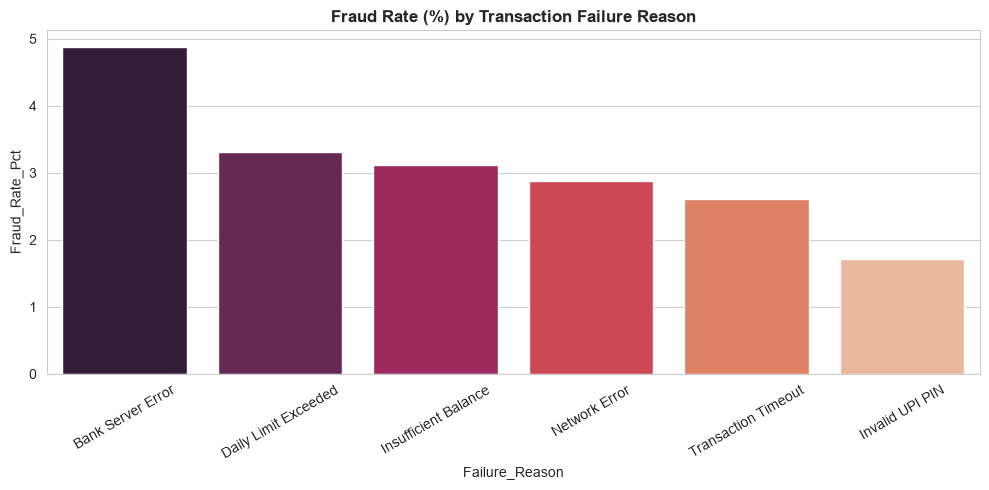

,Failure_Reason,Total_Failures,Fraud_Failures,Fraud_Rate_Mean,Fraud_Rate_Pct
0,Bank Server Error,123,6,0.048780,4.88
1,Daily Limit Exceeded,121,4,0.033058,3.31
2,Insufficient Balance,128,4,0.031250,3.12
4,Network Error,104,3,0.028846,2.88
5,Transaction Timeout,115,3,0.026087,2.61
3,Invalid UPI PIN,116,2,0.017241,1.72


In [11]:
failure_df = df[df['Failure_Reason'] != 'Not Applicable'].groupby('Failure_Reason').agg(
    Total_Failures=('Fraud_Label', 'count'),
    Fraud_Failures=('Fraud_Label', 'sum'),
    Fraud_Rate_Mean=('Fraud_Label', 'mean')
).reset_index()
failure_df['Fraud_Rate_Pct'] = (failure_df['Fraud_Rate_Mean'] * 100).round(2)
failure_df = failure_df.sort_values(by='Fraud_Rate_Pct', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=failure_df, x='Failure_Reason', y='Fraud_Rate_Pct', hue='Failure_Reason', palette='rocket', legend=False)
plt.title('Fraud Rate (%) by Transaction Failure Reason', fontsize=12, fontweight='bold')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(failure_df)